# Part 1: Preprocessing steps 
## Loading and merging the datasets

In [1]:
import pandas as pd

# Load the three datasets
proteins = pd.read_csv("proteins_npx_raw.csv")
metadata = pd.read_csv("sample_metadata.csv")
annotation = pd.read_csv("protein_annotation.csv")

# Inspect the dimensions of each dataset
print(proteins.shape)
print(metadata.shape)
print(annotation.shape)

# Inspect some column names
print(proteins.columns[:10])
print(metadata.columns[:10])

# Merge protein measurements with metadata using sample_kit_id
# This links each row to the corresponding participant and sampling time point
data = proteins.merge(metadata, on="sample_kit_id")

# Check whether the merge was successful
print(data.shape)

(867, 1482)
(867, 76)
(1481, 12)
Index(['sample_kit_id', 'AARSD1', 'ABHD14B', 'ABL1', 'ACAA1', 'ACAN', 'ACE2',
       'ACOX1', 'ACP5', 'ACP6'],
      dtype='str')
Index(['sample_kit_id', 'subject.subjectGuid', 'cohort.cohortGuid',
       'subject.biologicalSex', 'subject.ageGroup', 'sample.subjectAgeAtDraw',
       'sample.visitName', 'sample.daysSinceFirstVisit', 'cmv_status',
       'olink_plate_id'],
      dtype='str')
(867, 1557)


## Remove duplicates

Duplicate samples artificially inflate the sample size and can bias downstream analyses such as PCA, clustering, and statistical tests. Each biological sample should generally be represented only once unless technical replicates are intentionally included in the study design.

In [2]:
# Count duplicate rows
duplicate_rows = data.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_rows}")

Number of duplicate rows: 0


In [3]:
# Remove exact duplicate rows
data = data.drop_duplicates()

print(data.shape)

(867, 1557)


In [4]:
# Check whether sample IDs occur multiple times
duplicate_samples = data["sample_kit_id"].duplicated().sum()

print(f"Duplicate sample IDs: {duplicate_samples}")

Duplicate sample IDs: 0


## Investigating missing values

The number and percentage of missing values are calculated for every column.

Columns with more than 50% missing values are removed because they contain too little information for reliable statistical analysis. Remaining missing numeric values are replaced with the median.

Why?
Many statistical methods and machine-learning algorithms cannot handle missing values directly. Median imputation is used because the median is less influenced by extreme values than the mean.

In [5]:
# Calculate the number of missing values per column
missing_counts = data.isnull().sum()

# Calculate the percentage of missing values
missing_percentages = (data.isnull().sum() / len(data)) * 100

# Combine the results in a summary table
missing_table = pd.DataFrame({
    "Missing_Count": missing_counts,
    "Missing_Percentage": missing_percentages
})

# Display the columns with the most missing values
print(missing_table.sort_values(
    by="Missing_Percentage",
    ascending=False
).head(20))

# Remove columns with more than 50% missing values
# These usually contain too little information for reliable analysis
data = data.loc[:, missing_percentages < 50]

# Impute remaining missing values in numeric variables with the median
# The median is robust to outliers
for col in data.select_dtypes(include="number").columns:
    data[col] = data[col].fillna(data[col].median())

                                 Missing_Count  Missing_Percentage
cmv.igg_serology_interpretation            775           89.388697
cmv.igg_serology                           775           89.388697
infl.rf_igm_interpretation                 770           88.811995
infl.rf_iga_result                         770           88.811995
infl.rf_igm_result                         770           88.811995
infl.anti_ccp3                             770           88.811995
infl.anti_ccp31                            770           88.811995
infl.rf_iga_interpretation                 770           88.811995
chem.egfr_aa                               718           82.814302
chem.egfr_non_aa                           717           82.698962
DARS                                       711           82.006920
FGFR1OP                                    711           82.006920
CASC4                                      711           82.006920
LRMP                                       711           82.00

## Filtering low-quality samples

The variables pct_below_lod and n_missing_npx are used to identify samples with poor measurement quality.

Samples with more than 20% of proteins below the limit of detection are removed.
Samples with more than 50 missing NPX values are removed.

Why?
Samples with many undetectable or missing protein measurements may not accurately represent the participant’s true protein profile. Keeping them could introduce noise and distort the analysis.

The thresholds of 20% and 50 should ideally be justified using the distributions of these quality variables or the study’s quality-control guidelines.

In [6]:
# Inspect the distribution of the quality-control variables
print(data["n_missing_npx"].describe())
print(data["pct_below_lod"].describe())

# Remove samples with more than 20% of proteins below the limit of detection
# Such samples are less reliable
data = data[data["pct_below_lod"] <= 20]

# Remove samples with an extremely high number of missing NPX values
# The threshold can be adjusted after inspecting the distribution
data = data[data["n_missing_npx"] <= 50]

# Check how many samples remain
print(data.shape)

count    867.000000
mean       0.603230
std        1.620991
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        6.000000
Name: n_missing_npx, dtype: float64
count    867.000000
mean      10.510035
std        2.726735
min        3.700000
25%        8.600000
50%       10.500000
75%       12.400000
max       17.800000
Name: pct_below_lod, dtype: float64
(867, 1538)


## Correcting biologically impossible values

Values such as a BMI, weight, or height of zero are replaced with NaN. Extremely low or high BMI values are also treated as potentially invalid.

The resulting missing values are replaced with the median.

Why?
These values are likely caused by data-entry errors or missing values that were incorrectly coded as zero. Treating them as real measurements would influence summary statistics and later analyses.

The BMI thresholds of below 10 and above 60 are practical plausibility limits, but unusually extreme values should preferably be checked against the original data before being removed.

In [7]:
import numpy as np

# A BMI of 0 is biologically impossible
# Treat this value as missing data
data["am.bmi"] = data["am.bmi"].replace(0, np.nan)

# A body weight of 0 kg is impossible
data["am.weight"] = data["am.weight"].replace(0, np.nan)

# A height of 0 cm is impossible
data["am.height"] = data["am.height"].replace(0, np.nan)

# Check for extreme BMI values
# BMI > 60 of < 10 is meestal een invoerfout
data.loc[data["am.bmi"] > 60, "am.bmi"] = np.nan
data.loc[data["am.bmi"] < 10, "am.bmi"] = np.nan

# Impute the resulting missing values with the median
data["am.bmi"] = data["am.bmi"].fillna(data["am.bmi"].median())
data["am.weight"] = data["am.weight"].fillna(data["am.weight"].median())
data["am.height"] = data["am.height"].fillna(data["am.height"].median())

# Check the result
print(data[["am.bmi", "am.weight", "am.height"]].describe())

           am.bmi   am.weight   am.height
count  867.000000  867.000000  867.000000
mean    26.388697   76.257859  169.745582
std      4.071816   13.959351    7.718303
min     19.000000   51.300000  147.000000
25%     24.000000   65.100000  165.000000
50%     26.000000   74.500000  169.900000
75%     28.000000   85.000000  174.500000
max     45.000000  117.700000  190.500000


In [8]:
print(proteins.shape)
print(proteins.columns.tolist())
print(proteins.head())

(867, 1482)
['sample_kit_id', 'AARSD1', 'ABHD14B', 'ABL1', 'ACAA1', 'ACAN', 'ACE2', 'ACOX1', 'ACP5', 'ACP6', 'ACTA2', 'ACTN4', 'ACVRL1', 'ACY1', 'ADA', 'ADA2', 'ADAM15', 'ADAM22', 'ADAM23', 'ADAM8', 'ADAMTS13', 'ADAMTS15', 'ADAMTS16', 'ADAMTS8', 'ADCYAP1R1', 'ADGRB3', 'ADGRE2', 'ADGRE5', 'ADGRG1', 'ADGRG2', 'ADH4', 'ADM', 'AFP', 'AGER', 'AGR2', 'AGR3', 'AGRN', 'AGRP', 'AGXT', 'AHCY', 'AHSP', 'AIF1', 'AIFM1', 'AK1', 'AKR1B1', 'AKR1C4', 'AKT1S1', 'AKT3', 'ALCAM', 'ALDH1A1', 'ALDH3A1', 'ALPP', 'AMBN', 'AMBP', 'AMFR', 'AMIGO2', 'AMN', 'AMY2A', 'AMY2B', 'ANG', 'ANGPT1', 'ANGPT2', 'ANGPTL1', 'ANGPTL2', 'ANGPTL3', 'ANGPTL4', 'ANGPTL7', 'ANKRD54', 'ANPEP', 'ANXA10', 'ANXA11', 'ANXA3', 'ANXA4', 'ANXA5', 'AOC1', 'AOC3', 'APBB1IP', 'APEX1', 'APLP1', 'APOH', 'APOM', 'APP', 'APRT', 'AREG', 'ARG1', 'ARHGAP1', 'ARHGAP25', 'ARHGEF12', 'ARID4B', 'ARNT', 'ARSA', 'ARSB', 'ART3', 'ARTN', 'ASAH2', 'ASGR1', 'ATF2', 'ATG4A', 'ATOX1', 'ATP5IF1', 'ATP5PO', 'ATP6AP2', 'ATP6V1D', 'ATP6V1F', 'ATXN10', 'AXIN1', 'A

In [9]:
print(metadata.columns.tolist())

['sample_kit_id', 'subject.subjectGuid', 'cohort.cohortGuid', 'subject.biologicalSex', 'subject.ageGroup', 'sample.subjectAgeAtDraw', 'sample.visitName', 'sample.daysSinceFirstVisit', 'cmv_status', 'olink_plate_id', 'olink_batch_id', 'n_missing_npx', 'pct_below_lod', 'subject.birthYear', 'subject.ageAtFirstDraw', 'subject.race', 'subject.ethnicity', 'sample.visitDetails', 'sample.drawYear', 'am.bmi', 'am.height', 'am.weight', 'chem.alt', 'chem.albumin', 'chem.alkaline_phosphatase', 'chem.ast', 'chem.t_bili', 'chem.bun', 'chem.calcium', 'chem.co2', 'chem.cl', 'chem.creatinine', 'chem.egfr_aa', 'chem.egfr_non_aa', 'chem.globin', 'chem.glucose', 'chem.potassium', 'chem.protein', 'chem.sodium', 'bc.perc_basophils', 'bc.perc_eosinophils', 'bc.perc_lymphocytes', 'bc.perc_monocytes', 'bc.perc_neutrophils', 'bc.basophil_count', 'bc.eosinophil_count', 'bc.lymphocyte_count', 'bc.monocyte_count', 'bc.neutrophil_count', 'bc.hematocrit', 'bc.hemoglobin', 'bc.mch', 'bc.mchc', 'bc.mcv', 'bc.mpv', 'bc

## Imputing missing protein values

Missing NPX values are replaced with the median value of the corresponding protein.

Why?
PCA, standardization, and K-means clustering cannot process missing values. Median imputation produces a complete matrix while limiting the influence of outliers.

However, if a protein has a large proportion of missing values, it is usually better to remove that protein rather than impute many measurements.

In [19]:
# Keep only proteins that are still present after filtering
protein_cols = [
    col for col in proteins.columns
    if col in data.columns and col != "sample_kit_id"
]

X = data[protein_cols]

print(X.shape)

print("Total number of missing values:", X.isna().sum().sum())

print("\nNumber of proteins with missing values:")
print((X.isna().sum() > 0).sum())

(867, 1472)
Total number of missing values: 0

Number of proteins with missing values:
0


In [20]:
# Replace missing values with the median of each protein
X = X.fillna(X.median())
print(X.isna().sum().sum())

0


## Standardizing the protein measurements

StandardScaler transforms each protein so that it has approximately:

a mean of 0;
a standard deviation of 1.

Why?
Proteins can differ in their variation. Without standardization, proteins with larger variance would have a stronger influence on PCA and K-means clustering. Standardization allows the proteins to contribute on a more comparable scale.

Olink NPX values are already provided on a log2 scale, so an additional log transformation is generally not necessary.

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Remove sample identifier
X = proteins.drop(columns=["sample_kit_id"])

# Impute all remaining missing values
X = X.fillna(X.median())

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)

# Display the proportion of explained variance
print(pca.explained_variance_ratio_)

# Total variance explained by PC1 and PC2
print(sum(pca.explained_variance_ratio_))

[0.23619119 0.08669823]
0.32288942240409496


## Performing PCA

Principal Component Analysis reduces the large number of protein features to a smaller number of principal components. The first two components, PC1 and PC2, summarize the main patterns of variation in the protein data.

Why?
PCA makes it possible to visually inspect:

whether samples form clusters;
whether outliers are present;
whether samples separate according to biology;
whether technical batches influence the results.

The explained variance ratio shows how much of the total variation is captured by PC1 and PC2.

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Store the PCA results in a DataFrame
pca_df = pd.DataFrame(
    pca_result,
    columns=["PC1", "PC2"]
)

pca_df["sample_kit_id"] = data["sample_kit_id"].reset_index(drop=True)

metadata_vars = metadata[
    [
        "sample_kit_id",
        "subject.biologicalSex",
        "subject.ageGroup",
        "cmv_status",
        "olink_batch_id"
    ]
]

pca_df = pca_df.merge(
    metadata_vars,
    on="sample_kit_id"
)

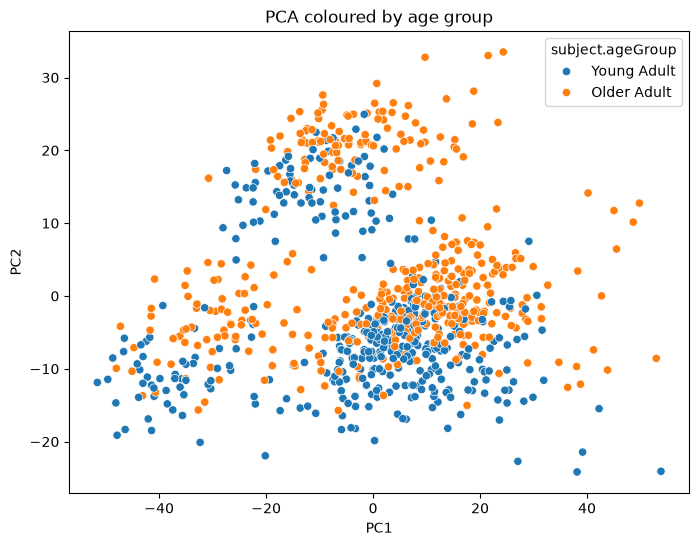

In [25]:
#pca coloured by age
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="subject.ageGroup"
)

plt.title("PCA coloured by age group")
# Label the axes
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

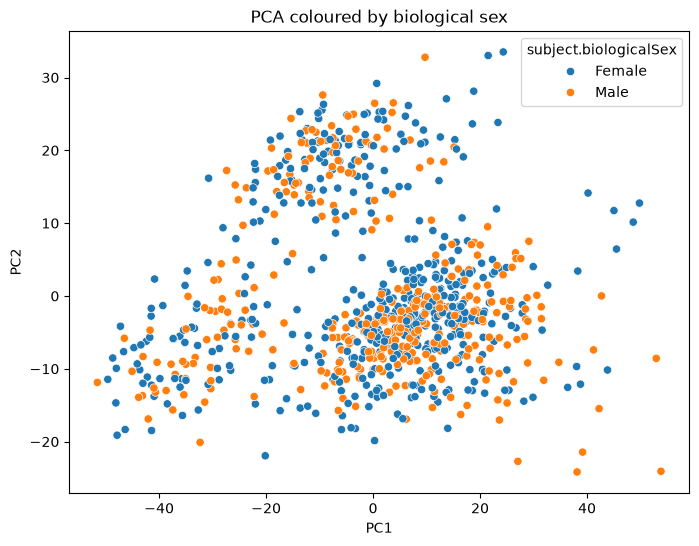

In [26]:
#pca coloured by sex
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="subject.biologicalSex"
)

plt.title("PCA coloured by biological sex")
# Label the axes
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

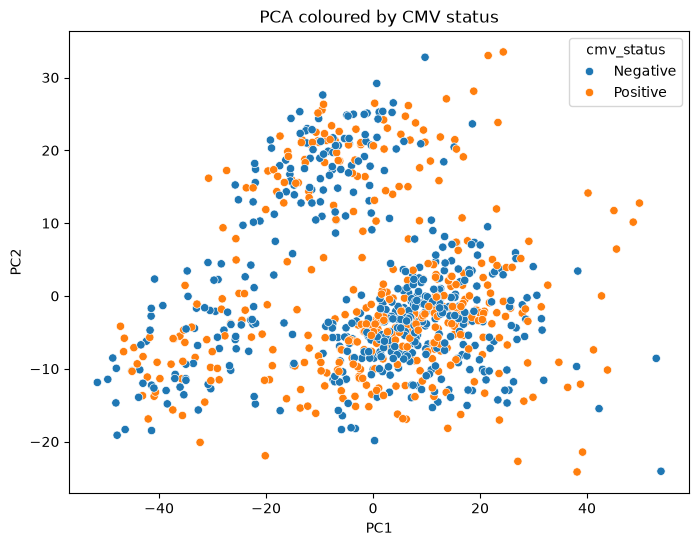

In [27]:
#pca coloured by CMV
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cmv_status"
)

plt.title("PCA coloured by CMV status")
# Label the axes
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

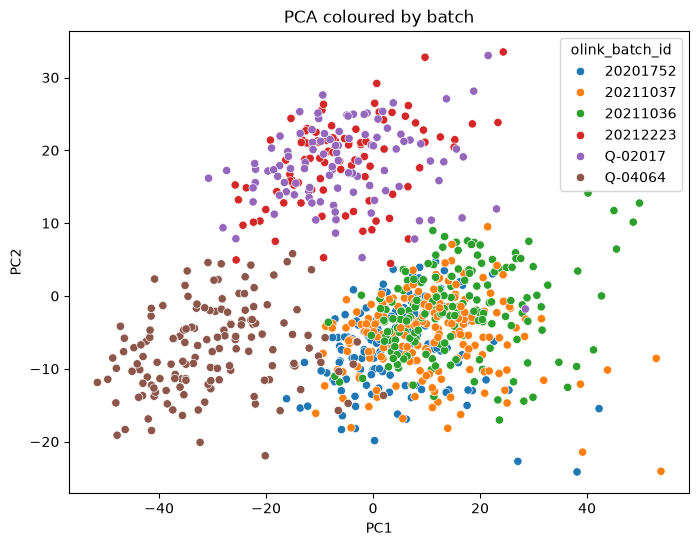

In [28]:
#pca coloured by batch
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="olink_batch_id"
)

plt.title("PCA coloured by batch")
# Label the axes
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

## Applying K-means clustering

K-means divides the samples into three groups based on similarities in their standardized protein profiles.

Why?
This is an exploratory, unsupervised method. It can reveal naturally occurring sample groups without using known labels such as age group or CMV status.

The choice of three clusters should not be arbitrary. It can be evaluated using methods such as the elbow method or silhouette score.

In [29]:
from sklearn.cluster import KMeans

# Create a K-means model with three clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

# Assign each sample to a cluster
clusters = kmeans.fit_predict(X_scaled)

# Add the cluster labels to the PCA DataFrame
pca_df["cluster"] = clusters

# Check how many samples belong to each cluster
print(pca_df["cluster"].value_counts())

cluster
2    527
1    192
0    148
Name: count, dtype: int64


C:\Users\justi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


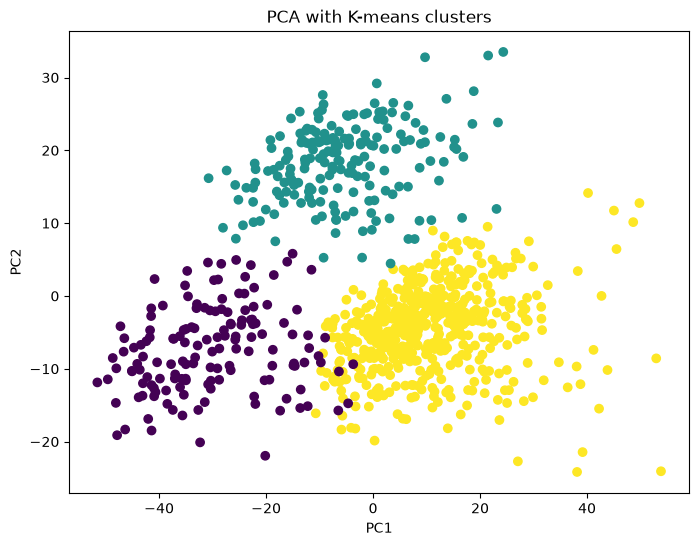

In [30]:
plt.figure(figsize=(8,6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["cluster"]
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA with K-means clusters")

plt.show()

In [31]:
pd.crosstab(
    pca_df["cluster"],
    pca_df["subject.ageGroup"]
)

subject.ageGroup,Older Adult,Young Adult
cluster,,
0,81,67
1,114,78
2,255,272


In [32]:
pd.crosstab(
    pca_df["cluster"],
    pca_df["subject.biologicalSex"]
)

subject.biologicalSex,Female,Male
cluster,,
0,88,60
1,120,72
2,283,244


In [33]:
pd.crosstab(
    pca_df["cluster"],
    pca_df["cmv_status"]
)

cmv_status,Negative,Positive
cluster,,
0,78,70
1,100,92
2,298,229


In [35]:
pd.crosstab(
    pca_df["cluster"],
    pca_df["olink_batch_id"]
)

olink_batch_id,20201752,20211036,20211037,20212223,Q-02017,Q-04064
cluster,,,,,,
0,5,0,0,1,0,142
1,0,0,0,91,101,0
2,151,176,197,0,1,2


This shows the proof of a batch effect!!

## Categorische variabelen coderen

In [34]:
from sklearn.preprocessing import LabelEncoder

# Maak een encoder aan
encoder = LabelEncoder()

# Zet geslacht om naar numerieke waarden
# Bijvoorbeeld Female=0 en Male=1
data["sex_encoded"] = encoder.fit_transform(
    data["subject.biologicalSex"]
)

# Zet leeftijdsgroep om naar numerieke waarden
data["agegroup_encoded"] = encoder.fit_transform(
    data["subject.ageGroup"]
)

# Zet CMV-status om naar numerieke waarden
data["cmv_encoded"] = encoder.fit_transform(
    data["cmv_status"]
)

# Controleer het resultaat
print(
    data[
        [
            "subject.biologicalSex",
            "sex_encoded",
            "subject.ageGroup",
            "agegroup_encoded"
        ]
    ].head()
)

  subject.biologicalSex  sex_encoded subject.ageGroup  agegroup_encoded
0                Female            0      Young Adult                 1
1                  Male            1      Young Adult                 1
2                Female            0      Young Adult                 1
3                  Male            1      Young Adult                 1
4                Female            0      Young Adult                 1


C:\Users\justi\AppData\Local\Temp\ipykernel_11444\300892289.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data["sex_encoded"] = encoder.fit_transform(
C:\Users\justi\AppData\Local\Temp\ipykernel_11444\300892289.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data["agegroup_encoded"] = encoder.fit_transform(
C:\Users\justi\AppData\Local\Temp\ipykernel_11444\300892289.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  